# Лаборатори 12. Transformers ашиглан монгол хэлний мэдээ ангилах

Eduge корпусын 9 ангилал дээр TF-IDF + логистик регресс болон гурван урьдчилан сургасан encoder-ийг харьцуулна. Эх дасгал нь transformers_text_classification.ipynb.zip архивт бий. Өгөгдлийг textclassification.zip архиваас уншина. Туршсан орчинд Python 3.12, PyTorch 2.11, transformers 4.57.3, datasets 4.8.5, accelerate 1.16.0, sentencepiece 0.2.3 ашиглав. Загварын хувилбаруудыг commit SHA-аар тогтоосон тул өмнө нь кэшлээгүй бол интернет хэрэгтэй.

In [1]:
from pathlib import Path
from shutil import copyfileobj
from tempfile import NamedTemporaryFile
from zipfile import ZipFile

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "textclassification.zip").is_file())
WORK = ROOT / ".work" / "lab11_12"

def eduge_file(name):
    member = f"textclassification/{name}"
    path = WORK / member
    with ZipFile(ROOT / "textclassification.zip") as archive:
        size = archive.getinfo(member).file_size
        if path.is_file() and path.stat().st_size == size:
            return path
        path.parent.mkdir(parents=True, exist_ok=True)
        with NamedTemporaryFile(dir=path.parent, delete=False) as temporary:
            temp_path = Path(temporary.name)
            try:
                with archive.open(member) as source:
                    copyfileobj(source, temporary)
                temporary.close()
                temp_path.replace(path)
            finally:
                temp_path.unlink(missing_ok=True)
    return path

In [2]:
import gc
import os
import time

os.environ.setdefault("HF_HOME", str(ROOT / ".work" / "huggingface"))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from sklearn.model_selection import train_test_split
from transformers import set_seed

SEED = 42
set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
if DEVICE == "cuda":
    torch.set_float32_matmul_precision("high")
print(f"torch={torch.__version__}, transformers={transformers.__version__}, device={DEVICE}")
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(), "bfloat16:", torch.cuda.is_bf16_supported())

MAIN_MODEL = "tugstugi/bert-base-mongolian-cased"
MODELS = {
    MAIN_MODEL: ("f07c2d5cb25c1fc6baac69a875e8e1bbd040872a", "pytorch_model.bin"),
    "FacebookAI/xlm-roberta-base": ("e73636d4f797dec63c3081bb6ed5c7b0bb3f2089", "model.safetensors"),
    "google-bert/bert-base-multilingual-cased": ("3f076fdb1ab68d5b2880cb87a0886f315b8146f8", "model.safetensors"),
}
CONFIG = {
    "sample_size": 4800,
    "batch_size": 16,
    "eval_batch_size": 32,
    "epochs": 2,
}
print(CONFIG)

/home/jmlu/MySecretBase/Machine-Learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch=2.11.0+cu128, transformers=4.57.3, device=cuda
NVIDIA GeForce RTX 5070 Ti bfloat16: True
{'sample_size': 4800, 'batch_size': 16, 'eval_batch_size': 32, 'epochs': 2}


## 1–2. Өгөгдлийг цэвэрлэх, тархалтыг шинжлэх

Хоосон шошго, 20 тэмдэгтээс богино буюу тэнцүү бичвэр болон давхардсан нийтлэлийг хасав. Ижил бичвэр нэгээс олон ангилалтай байсан ч давхардлыг хуваахаас өмнө арилгав.

In [3]:
df = pd.read_csv(eduge_file("eduge.csv"))
df.columns = df.columns.str.strip()
before = len(df)
df = df.dropna(subset=["label", "news"]).copy()
df["label"] = df["label"].str.strip()
df["news"] = df["news"].str.strip()
df = df[df["label"].ne("") & df["news"].str.len().gt(20)]
df = df.drop_duplicates(subset=["news"]).reset_index(drop=True)
print(f"Эх={before:,} → цэвэр={len(df):,} (хассан={before - len(df):,})")
df.head(3)

Эх=75,661 → цэвэр=73,875 (хассан=1,786)


,news,label
0,Киноны кадраас «Юрийн галавын үе» кино проката...,урлаг соёл
1,“Universal” кино компани Жадд Апатоугийн найру...,урлаг соёл
2,Баз Лурманы бүтээж байгаа “The Get Down” хөгжм...,урлаг соёл


label
улс төр         13405
спорт           13401
эдийн засаг     12349
хууль            8164
урлаг соёл       6966
технологи        5431
байгал орчин     4937
эрүүл мэнд       4781
боловсрол        4441
Name: count, dtype: int64

Нийт ангилал: 9
Хамгийн их/бага харьцаа: 3.0x


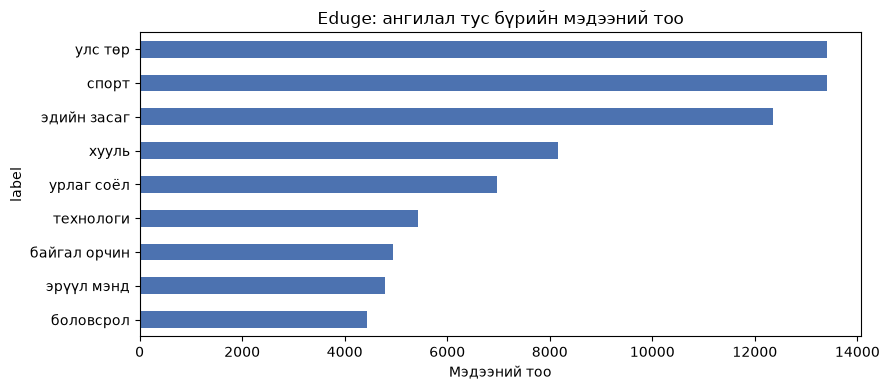

In [4]:
counts = df["label"].value_counts()
print(counts)
print("\nНийт ангилал:", df["label"].nunique())
print("Хамгийн их/бага харьцаа: %.1fx" % (counts.max() / counts.min()))

fig, ax = plt.subplots(figsize=(9, 4))
counts.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Eduge: ангилал тус бүрийн мэдээний тоо")
ax.set_xlabel("Мэдээний тоо")
plt.tight_layout()
plt.show()

count    73875.0
mean       320.2
std        424.4
min          1.0
25%         99.0
50%        167.0
75%        360.0
max       9679.0
Name: n_words, dtype: float64


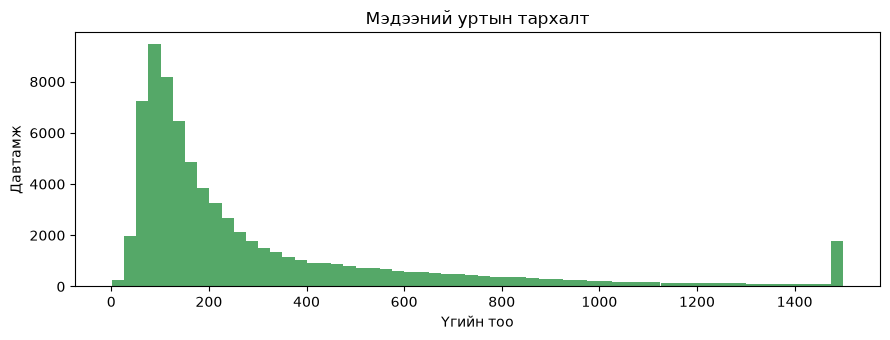

In [5]:
# Текстийн урт (үгээр)
df["n_words"] = df["news"].map(lambda text: len(text.split()))
print(df["n_words"].describe().round(1))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df["n_words"].clip(upper=1500), bins=60, color="#55A868")
ax.set_xlabel("Үгийн тоо"); ax.set_ylabel("Давтамж")
ax.set_title("Мэдээний уртын тархалт")
plt.tight_layout(); plt.show()

## 3. Ижил stratified хуваалт

Цэвэр корпусоос ангийн эзлэх хувийг хадгалж 4,800 мэдээ сонгов. 70% сургалт, 15% баталгаажуулалт, 15% тестэд хуваав. Бүх загвар ижил мөрийн хуваалтыг ашиглана. Ангилал бүрээс ижил тоогоор авбал жинтэй loss-ийн туршилтад корпусын ангийн зөрүү алдагдана.

In [6]:
df_s, _ = train_test_split(df, train_size=CONFIG["sample_size"], random_state=SEED, stratify=df["label"])
df_s = df_s.copy()
labels = sorted(df_s["label"].unique())
assert len(labels) == 9
label2id = {label: i for i, label in enumerate(labels)}
id2label = {i: label for label, i in label2id.items()}
df_s["y"] = df_s["label"].map(label2id)

train_df, temporary = train_test_split(df_s, test_size=0.30, random_state=SEED, stratify=df_s["y"])
val_df, test_df = train_test_split(temporary, test_size=0.50, random_state=SEED, stratify=temporary["y"])
splits = train_df, val_df, test_df

partition = pd.DataFrame({
    name: frame["label"].value_counts()
    for name, frame in zip(("train", "validation", "test"), splits)
}).loc[labels]
partition.loc["Нийт"] = partition.sum()
display(partition)
assert len(train_df.index.union(val_df.index).union(test_df.index)) == sum(map(len, splits)) == len(df_s)
assert all(part["y"].nunique() == len(labels) for part in splits)

,train,validation,test
label,,,
байгал орчин,225,48,48
боловсрол,201,43,44
спорт,610,131,130
технологи,247,53,53
улс төр,610,130,131
урлаг соёл,317,68,68
хууль,371,80,79
эдийн засаг,561,120,121
эрүүл мэнд,218,47,46


## 4. TF-IDF + логистик регресс

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

t0 = time.time()
vec = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
Xtr = vec.fit_transform(train_df["news"])
Xte = vec.transform(test_df["news"])

clf = LogisticRegression(max_iter=1000, C=5.0, random_state=SEED)
clf.fit(Xtr, train_df["y"])
pred_base = clf.predict(Xte)

BASELINE = {
    "accuracy": accuracy_score(test_df["y"], pred_base),
    "macro_f1": f1_score(test_df["y"], pred_base, average="macro"),
}
BASELINE["weighted_f1"] = f1_score(test_df["y"], pred_base, average="weighted")
BASELINE["train_and_test_s"] = time.time() - t0
print("Baseline:", {k: round(v, 4) for k, v in BASELINE.items()})
print("Хугацаа: %.1f сек" % (time.time() - t0))

Baseline: {'accuracy': 0.8694, 'macro_f1': 0.8582, 'weighted_f1': 0.8677, 'train_and_test_s': 3.3472}
Хугацаа: 3.3 сек


## 5. Токенжуулалт ба Асуулт 1

Fertility-г ижил 300 сургалтын мэдээний тусгай тэмдэггүй subword токены нийлбэрийг зайгаар тасалсан үгийн нийлбэрт хувааж тооцов. 256 токеноос урт мэдээний хувийг Mongolian BERT-ийн токенжуулагчаар цэвэрлэсэн бүх корпус дээр тусгай токеныг оролцуулан хэмжив. Mongolian BERT-ийн репод нэмсэн PAD ID нь embedding-ээс гадуур тул SentencePiece загварт байгаа [PAD] токеныг хэрэглэв.

In [8]:
from huggingface_hub import snapshot_download
from huggingface_hub.errors import LocalEntryNotFoundError
from transformers import AutoConfig, AutoTokenizer

def model_source(model_id, revision, weights):
    patterns = ["config.json", "*tokenizer*.json", "special_tokens_map.json", "added_tokens.json",
                "*.model", "vocab.txt", weights]
    try:
        source = Path(snapshot_download(model_id, revision=revision, allow_patterns=patterns, local_files_only=True))
        if (source / weights).is_file():
            return source
    except LocalEntryNotFoundError:
        pass
    return Path(snapshot_download(model_id, revision=revision, allow_patterns=patterns))

sources = {mid: model_source(mid, *release) for mid, release in MODELS.items()}
tokenizers = {}
for model_id, source in sources.items():
    tok = AutoTokenizer.from_pretrained(source, use_fast=model_id != MAIN_MODEL)
    vocab_size = AutoConfig.from_pretrained(source).vocab_size
    assert tok.vocab_size == vocab_size
    if tok.pad_token_id is None or not 0 <= tok.pad_token_id < vocab_size:
        assert "[PAD]" in tok.get_vocab() and 0 <= tok.get_vocab()["[PAD]"] < vocab_size
        tok.pad_token = "[PAD]"
    tokenizers[model_id] = tok
    print(f"{model_id}: {type(tok).__name__}, vocab={vocab_size:,}, PAD={tok.pad_token!r}/{tok.pad_token_id}")
tokenizer = tokenizers[MAIN_MODEL]

sample = "Шударга өрсөлдөөн, хэрэглэгчийн төлөө газар хяналт шалгалтаа эрчимжүүлж байна."
print("Өгүүлбэр:", sample)
print("Токенууд:", tokenizer.tokenize(sample))

sample_news = train_df["news"].sample(n=min(300, len(train_df)), random_state=SEED).tolist()
sample_words = sum(len(text.split()) for text in sample_news)
fertility = {}
for model_id, tok in tokenizers.items():
    token_total = sum(len(ids) for ids in tok(
        sample_news, truncation=False, add_special_tokens=False, verbose=False
    )["input_ids"])
    fertility[model_id] = token_total / sample_words
display(pd.Series(fertility, name="fertility (токен/үг)").round(4))

def token_lengths(texts, tok, batch_size=256):
    return [
        len(ids)
        for start in range(0, len(texts), batch_size)
        for ids in tok(texts[start:start + batch_size], add_special_tokens=True,
                       truncation=False, verbose=False)["input_ids"]
    ]

# Цэвэрлэсэн бүх корпусыг тооцсон тул sampling-ийн алдаа орохгүй.
lengths = np.array(token_lengths(df["news"].tolist(), tokenizer))
print(f"Нийт={len(lengths):,}; медиан={np.median(lengths):.0f}; P90={np.percentile(lengths, 90):.0f}")
print(f">256 токен: {(lengths > 256).sum():,}/{len(lengths):,} ({(lengths > 256).mean():.2%})")


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching 5 files: 100%|██████████| 5/5 [00:51<00:00, 10.30s/it]

Fetching 5 files: 100%|██████████| 5/5 [00:51<00:00, 10.30s/it]

tugstugi/bert-base-mongolian-cased: AlbertTokenizer, vocab=32,000, PAD='[PAD]'/3


The tokenizer you are loading from '/home/jmlu/MySecretBase/Machine-Learning/.work/huggingface/hub/models--google-bert--bert-base-multilingual-cased/snapshots/3f076fdb1ab68d5b2880cb87a0886f315b8146f8' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


FacebookAI/xlm-roberta-base: XLMRobertaTokenizerFast, vocab=250,002, PAD='<pad>'/1
google-bert/bert-base-multilingual-cased: BertTokenizerFast, vocab=119,547, PAD='[PAD]'/0
Өгүүлбэр: Шударга өрсөлдөөн, хэрэглэгчийн төлөө газар хяналт шалгалтаа эрчимжүүлж байна.
Токенууд: ['▁Шударга', '▁өрсөлдөөн', ',', '▁хэрэглэгчийн', '▁төлөө', '▁газар', '▁хяналт', '▁шалгалтаа', '▁эрчимжүүлж', '▁байна', '.']


tugstugi/bert-base-mongolian-cased          1.4253
FacebookAI/xlm-roberta-base                 1.9083
google-bert/bert-base-multilingual-cased    3.1025
Name: fertility (токен/үг), dtype: float64

Нийт=73,875; медиан=249; P90=1054
>256 токен: 36,010/73,875 (48.74%)


**Хариулт 1.** Цэвэрлэсэн 73,875 мэдээний 36,010 буюу **48.74%** нь 256 токеноос урт. 256 токеноор хязгаарлахад урт нийтлэлийн дэлгэрэнгүй тайлбар, төгсгөлийн дүгнэлт эсвэл сүүлд тодорхойлсон үйл явдлын үр дүн хасагдана. Сэдвийг гарчиг, эхний догол мөрөнд шууд өгсөн мэдээний хувьд эхний хэсэг ихэнхдээ хүрэлцэнэ. Сэдвийн гол баримт хожуу ирдэг мэдээнд таслалт нөлөөлж болохыг доорх марафоны жишээ харууллаа.

## 6–8. Dataset, dynamic padding ба Trainer

Batch доторх хамгийн урт жишээнд тааруулан padding хийнэ. Бүх сургалтыг ижил seed, 2e-5 learning rate, 0.01 weight decay, 0.10 warmup, 16/32 train/eval batch-аар эхлүүлэв. Validation macro-F1-р хамгийн сайн epoch-ийн checkpoint сонгож, early stopping-ийн patience-ийг нэг epoch болгосон. Сургалтын нийт секундэд validation болон checkpoint хадгалалт орно. Epoch-ийн дундаж секундэд зөвхөн сургалтын цикл орно. 256 токентой эхний сургалтын үед GPU-г өөр процесс давхар ашиглаж байсан. Иймээс хэмжсэн секундийг төхөөрөмжийн ачааллаас хамаарах хугацаа гэж үзнэ.

In [9]:
from time import perf_counter
from tempfile import TemporaryDirectory

from datasets import Dataset, disable_progress_bar
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoModelForSequenceClassification, DataCollatorWithPadding, EarlyStoppingCallback,
    Trainer, TrainerCallback, TrainingArguments, set_seed,
)

disable_progress_bar()

def encode_articles(tok, texts, max_length, head_tail=False):
    if not head_tail:
        return tok(texts, truncation=True, max_length=max_length)
    budget = max_length - tok.num_special_tokens_to_add(pair=False)
    clip = budget // 2
    batch = tok(texts, add_special_tokens=False, truncation=False)["input_ids"]
    return {
        "input_ids": [
            tok.build_inputs_with_special_tokens(ids[:clip] + ids[-(budget - clip):] if len(ids) > budget else ids)
            for ids in batch
        ]
    }

def encode_split(frame, tok, max_length, head_tail=False):
    dataset = Dataset.from_pandas(
        frame[["news", "y"]].rename(columns={"y": "labels"}), preserve_index=False
    )
    encoded = dataset.map(
        lambda batch: encode_articles(tok, batch["news"], max_length, head_tail),
        batched=True, remove_columns=["news"],
    )
    assert max(map(max, encoded["input_ids"])) < tok.vocab_size
    return encoded

def compute_metrics(eval_pred):
    logits, actual = eval_pred
    predicted = logits.argmax(axis=-1)
    return {
        "accuracy": accuracy_score(actual, predicted),
        "macro_f1": f1_score(actual, predicted, average="macro", zero_division=0),
        "weighted_f1": f1_score(actual, predicted, average="weighted", zero_division=0),
    }

class EpochTimer(TrainerCallback):
    def __init__(self):
        self.seconds = []

    def on_epoch_begin(self, args, state, control, **kwargs):
        self.start = perf_counter()

    def on_epoch_end(self, args, state, control, **kwargs):
        self.seconds.append(perf_counter() - self.start)

class WeightedTrainer(Trainer):
    def __init__(self, *args, weights, **kwargs):
        super().__init__(*args, **kwargs)
        self.weights = weights
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**{key: value for key, value in inputs.items() if key != "labels"})
        loss = torch.nn.functional.cross_entropy(
            outputs.logits.float(), labels, weight=self.weights.to(labels.device)
        )
        return (loss, outputs) if return_outputs else loss

counts_train = train_df["y"].value_counts().sort_index()
class_weights = torch.tensor(
    compute_class_weight("balanced", classes=np.arange(len(labels)), y=train_df["y"]),
    dtype=torch.float32,
)

def run_experiment(name, model_id=MAIN_MODEL, max_length=256, frozen=0, weighted=False, keep_model=False):
    set_seed(SEED)
    tok = tokenizers[model_id]
    ds_train, ds_val, ds_test = (encode_split(part, tok, max_length) for part in splits)
    model = AutoModelForSequenceClassification.from_pretrained(
        sources[model_id], num_labels=len(labels), id2label=id2label, label2id=label2id,
        pad_token_id=tok.pad_token_id,
    )
    if frozen:
        model.base_model.embeddings.requires_grad_(False)
        model.base_model.encoder.layer[:frozen].requires_grad_(False)
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    collator = DataCollatorWithPadding(tok, pad_to_multiple_of=8 if DEVICE == "cuda" else None)
    timer = EpochTimer()
    with TemporaryDirectory(prefix="checkpoint-", dir=WORK) as checkpoint_dir:
        args = TrainingArguments(
            output_dir=checkpoint_dir,
            learning_rate=2e-5, weight_decay=0.01, warmup_ratio=0.1,
            per_device_train_batch_size=CONFIG["batch_size"],
            per_device_eval_batch_size=CONFIG["eval_batch_size"],
            num_train_epochs=CONFIG["epochs"],
            eval_strategy="epoch", save_strategy="epoch",
            load_best_model_at_end=True, metric_for_best_model="macro_f1", greater_is_better=True,
            save_total_limit=1, save_only_model=True,
            logging_steps=20, disable_tqdm=True, report_to="none", seed=SEED,
            bf16=DEVICE == "cuda" and torch.cuda.is_bf16_supported(),
            fp16=DEVICE == "cuda" and not torch.cuda.is_bf16_supported(),
        )
        trainer_type = WeightedTrainer if weighted else Trainer
        kwargs = {"weights": class_weights} if weighted else {}
        trainer = trainer_type(
            model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
            data_collator=collator, compute_metrics=compute_metrics, processing_class=tok,
            callbacks=[timer, EarlyStoppingCallback(early_stopping_patience=1)], **kwargs,
        )
        start = perf_counter()
        trainer.train()
        elapsed = perf_counter() - start
        prediction = trainer.predict(ds_test)
        assert np.array_equal(prediction.label_ids, test_df["y"].to_numpy())
        metrics = {
            "experiment": name, "model": model_id, "max_length": max_length, "frozen": frozen,
            "weighted": weighted, "train_n": len(ds_train), "val_n": len(ds_val), "test_n": len(ds_test),
            "params": total, "trainable_params": trainable, "epochs": len(timer.seconds),
            "train_s": elapsed, "epoch_s": np.mean(timer.seconds),
            "best_val_macro_f1": trainer.state.best_metric,
            **{key.removeprefix("test_"): value for key, value in prediction.metrics.items() if key in {
                "test_accuracy", "test_macro_f1", "test_weighted_f1"
            }},
        }
        history = pd.DataFrame(trainer.state.log_history)
        if keep_model:
            trainer.save_model(WORK / "eduge_bert_final")
            return metrics, history, prediction, trainer
    del trainer, model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return metrics

def compare(runs, columns):
    display(pd.DataFrame(runs).set_index("experiment")[columns].round(4))


In [10]:
main, history, pred_out, trainer = run_experiment("256 / үндсэн", keep_model=True)
main_columns = ["train_n", "val_n", "test_n", "epochs", "accuracy", "macro_f1", "weighted_f1", "train_s"]
compare([main], main_columns)
print(f"Загвар болон tokenizer: {(WORK / 'eduge_bert_final').relative_to(ROOT)}")

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /home/jmlu/MySecretBase/Machine-Learning/.work/huggingface/hub/models--tugstugi--bert-base-mongolian-cased/snapshots/f07c2d5cb25c1fc6baac69a875e8e1bbd040872a and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 5, 'bos_token_id': 4}.


{'loss': 2.1738, 'grad_norm': 8.418065071105957, 'learning_rate': 9.047619047619049e-06, 'epoch': 0.09523809523809523}


{'loss': 1.9641, 'grad_norm': 7.602713108062744, 'learning_rate': 1.8571428571428575e-05, 'epoch': 0.19047619047619047}


{'loss': 1.6493, 'grad_norm': 8.399761199951172, 'learning_rate': 1.9100529100529103e-05, 'epoch': 0.2857142857142857}


{'loss': 1.3191, 'grad_norm': 7.40188455581665, 'learning_rate': 1.8042328042328044e-05, 'epoch': 0.38095238095238093}


... (17 outputs left out)

{'loss': 0.3248, 'grad_norm': 3.7450342178344727, 'learning_rate': 5.291005291005291e-08, 'epoch': 2.0}


{'eval_loss': 0.3682878315448761, 'eval_accuracy': 0.8875, 'eval_macro_f1': 0.8755279593934074, 'eval_weighted_f1': 0.8874127528616486, 'eval_runtime': 1.0155, 'eval_samples_per_second': 709.004, 'eval_steps_per_second': 22.649, 'epoch': 2.0}
{'train_runtime': 49.226, 'train_samples_per_second': 136.513, 'train_steps_per_second': 8.532, 'train_loss': 0.6875865209670294, 'epoch': 2.0}


,train_n,val_n,test_n,epochs,accuracy,macro_f1,weighted_f1,train_s
experiment,,,,,,,,
256 / үндсэн,3360,720,720,2,0.8736,0.8667,0.8734,49.4017


Загвар болон tokenizer: .work/lab11_12/eduge_bert_final


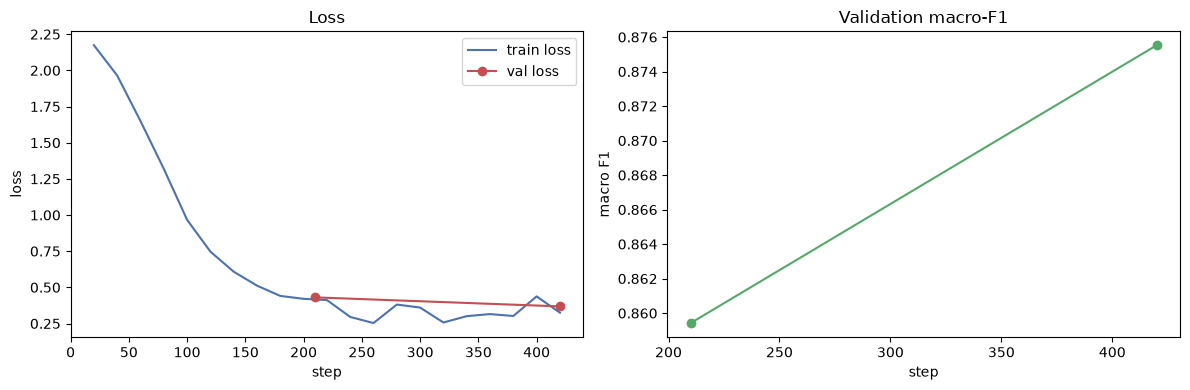

In [11]:
# Сургалтын явцыг графикаар харуулах
hist = history
tr = hist.dropna(subset=["loss"])
ev = hist.dropna(subset=["eval_loss"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(tr["step"], tr["loss"], label="train loss", color="#4C72B0")
axes[0].plot(ev["step"], ev["eval_loss"], "o-", label="val loss", color="#C44E52")
axes[0].set_xlabel("step"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[0].set_title("Loss")

axes[1].plot(ev["step"], ev["eval_macro_f1"], "o-", color="#55A868")
axes[1].set_xlabel("step"); axes[1].set_ylabel("macro F1")
axes[1].set_title("Validation macro-F1")
plt.tight_layout(); plt.show()

## 9. Тестийн үнэлгээ ба Асуулт 2

In [12]:
y_true = test_df["y"].to_numpy()
y_pred = pred_out.predictions.argmax(axis=-1)
print(classification_report(y_true, y_pred, labels=np.arange(len(labels)),
                            target_names=labels, digits=3, zero_division=0))

              precision    recall  f1-score   support

байгал орчин      0.878     0.750     0.809        48
   боловсрол      0.805     0.750     0.776        44
       спорт      0.955     0.969     0.962       130
   технологи      0.857     0.792     0.824        53
     улс төр      0.831     0.863     0.846       131
  урлаг соёл      0.925     0.912     0.919        68
       хууль      0.920     0.873     0.896        79
 эдийн засаг      0.788     0.860     0.822       121
  эрүүл мэнд      0.936     0.957     0.946        46

    accuracy                          0.874       720
   macro avg      0.877     0.858     0.867       720
weighted avg      0.875     0.874     0.873       720



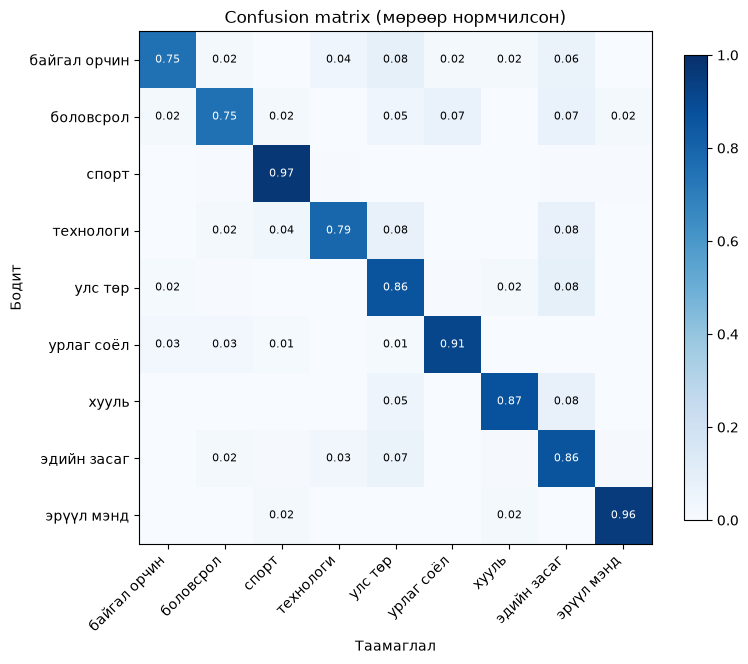

Хамгийн том диагоналиас гадуурх нүд: улс төр → эдийн засаг (11/131, 8.4%)


In [13]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_xlabel("Таамаглал"); ax.set_ylabel("Бодит")
ax.set_title("Confusion matrix (мөрөөр нормчилсон)")
for i in range(len(labels)):
    for j in range(len(labels)):
        if cm[i, j] > 0.01:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
offdiag = cm.copy()
np.fill_diagonal(offdiag, 0.0)
src, dst = np.unravel_index(offdiag.argmax(), offdiag.shape)
n_confused = ((y_true == src) & (y_pred == dst)).sum()
count_src = (y_true == src).sum()
print(f"Хамгийн том диагоналиас гадуурх нүд: {labels[src]} → {labels[dst]} ({n_confused}/{count_src}, {offdiag[src, dst]:.1%})")

**Хариулт 2.** Мөрөөр нормчилсон матрицын хамгийн их будилаан нь **улс төр → эдийн засаг** (11/131 буюу 8.4%). Сургалтад эдгээр ангид 610, 561 мэдээ байв. УИХ-ын төсвийн шийдвэр, Засгийн газрын өр, төрийн худалдан авалт гэх мэт мэдээ хоёр сэдвийн үг хэллэгийг зэрэг агуулдаг. Шалгасан жишээнүүд болон сургалтын тооноос харахад сэдвийн давхцал нь энэ хосын ангийн тооны зөрүүнээс илүү боломжит тайлбар юм.

## 10. Алдааны шинжилгээ ба Даалгавар 5

Үндсэн загварын буруу ангилсан нийтлэлээс softmax утгаар хамгийн өндөр 20-ийг урьдчилан тогтоосон дүрмээр сонгов. Хүснэгтэд эхний 160 тэмдэгтээр хайхад дөхөм үзүүлэв. Дараагийн тайлбарт бүтэн нийтлэл болон загварын харсан эхний 256 токеныг уншиж, шошгын алдаа, олон сэдэвт, загварын алдаа, таслалт гэсэн дөрвөн ангиллаас нэгийг сонгов. Таслалт гэж дүгнэхдээ ангиллыг илтгэх мэдээлэл тасалсны дараа гарч ирсэн эсэхийг шалгав.

In [14]:
probs = torch.softmax(torch.tensor(pred_out.predictions), dim=-1).numpy()
errors = test_df[["news", "label"]].assign(
    prediction=[id2label[i] for i in y_pred], confidence=probs.max(axis=1),
    tokens=token_lengths(test_df["news"].tolist(), tokenizer),
)
review = (errors.loc[y_pred != y_true].sort_values("confidence", ascending=False, kind="stable")
          .head(20).reset_index(names="eduge_id"))
review.index += 1
review_output = review.assign(news=review["news"].str.slice(0, 160))
with pd.option_context("display.max_colwidth", 180):
    display(review_output.round({"confidence": 3}))
print(f"Нийт алдаа: {(y_pred != y_true).sum()} / {len(y_true)}")
print("Бүтэн эхийг харах жишээ: print(review.loc[1, 'news'])")

,eduge_id,news,label,prediction,confidence,tokens
1,40845,Айлын хаус ухдаг удаа дараагийн үйлдэлтэй этгээдийг цагдаагийн ажилтнууд илрүүлжээ . Өнгөрсөн оны гуравдугаар сараас эхлэн голдуу айлын хаусаас үнэт эдлэл хулга,улс төр,хууль,0.976,109
2,47839,"Чөлөөт бөхийн улсын шигшээ багийн дасгалжуулагч, профессор доктор, олон улсын хэмжээний мастер Бямбаренчингийн Баяраатай ярилцлаа. Энэ хүний онцлог нь гэвэл ажи",эрүүл мэнд,спорт,0.974,2268
3,44627,Авлигатай тэмцэх газраас өнөөдөр хэвлэлийн хурал хийж Ерөнхий сайдын ахлах зөвлөх Л.Гансүх нарт холбогдох хэргийн хүрээнд тус газраас ямар ямар үйл ажиллагаануу,эдийн засаг,хууль,0.971,525
4,63729,"JoomlaXTC баг нь Joomla! CMS-ийн төрөл бүрийн шинэлэг, дэвшилтэт темплейт загварууд, компонент, модуль, нэмэлт плагин зэргийг боловсруулж Жуумла системийг ашигл",байгал орчин,технологи,0.963,825
5,58480,1998 оноос хойш Дэлхийн хөл бөмбөгийн холбооны ерөнхийлөгчөөр ажилласан Сепп Блаттер өнөөдөр үүрэгт ажлаа хүлээлгэн өгсөн талаар BBC болон CNN агентлаг онцоллоо,боловсрол,спорт,0.960,148
6,59643,"""SBN"" телевизийн уран бүтээлчдийн бүтээж байгаа ""Гэр"" олон ангит уран сайхны киноны зураг авалтыг сурвалжлахаар Гоодойн аманд очлоо. Үдийн 12 цаг арай болоогүй",боловсрол,урлаг соёл,0.955,2847
7,44916,"Эдийн засаг, нийгмийг 2016 онд хөгжүүлэх үндсэн чиглэл батлах тухай Улсын Их Хурлын тогтоолын төслийг хэлэлцэх эсэхийг УИХ шийдлээ. Хуралдаанд хууль санаачлагчи",эдийн засаг,улс төр,0.948,246
8,42571,"Ерөнхийлөгчийн зарлигийг УИХ-ын гишүүн, ЗГХЭГ-ын дарга, Монгол Улсын сайд Ч.Сайханбилэг, Нийслэлийн Засаг дарга бөгөөд Улаанбаатар хотын захирагч Э.Бат-Үүл нарт",эдийн засаг,улс төр,0.946,550
9,41272,"Тариаланчид дотоодын хэрэгцээгээ 100 хувь хангах буудай тариалсан гэж байгаа боловч гурил үйлдвэрлэгчид эсрэг байр суурьтай байгаа юм. Өөрөөр хэлбэл, Оросоос бу",улс төр,эдийн засаг,0.942,785
10,56090,"Олон овоотын уурхайн төсөл амжилттай болж чадаагүй тул ""Жаст"" групп ""Хадгаламж"" банкийг алдагдалд оруулсан гэж төв банкныхан мэдэгдэж байна. ""Жаст"" группын захи",хууль,эдийн засаг,0.936,1216


Нийт алдаа: 91 / 720
Бүтэн эхийг харах жишээ: print(review.loc[1, 'news'])


### Даалгавар 5. Гараар шалгасан үр дүн

Энэ нь хадгалсан сургалтын үр дүнд гарсан 20 алдааны үнэлгээ. Мөрийн дугаар нь дээрх цэвэрлэсэн Eduge өгөгдлийн индекс. Нийтлэлийн гол сэдвээр эх шошгыг үнэлэв. Хоёр сэдэв үнэхээр өрнөсөн бол «олон сэдэвт» гэж тэмдэглэв. Тасалсан хэсэгт эх шошгыг дэмжих онцгой баримт байгаа бол таслалт нөлөөлсөн байж болзошгүй гэж үзэв.

| № | Eduge мөр | Үнэлгээ | Бүтэн мэдээнээс харсан үндэслэл |
|---:|---:|---|---|
| 1 | 40845 | Шошгын алдаа | Гол үйл явдал нь цуврал хулгайн хэрэг, сэжигтнийг баривчилсан ажиллагаа. Улс төрчийг хохирогчдын нэгээр дурджээ. |
| 2 | 47839 | Шошгын алдаа | Чөлөөт бөхийн шигшээ багийн дасгалжуулагчтай хийсэн ярилцлага бүхэлдээ тамирчдын амжилт, бэлтгэл, барилдааны арга зүйг өгүүлнэ. |
| 3 | 44627 | Шошгын алдаа | АТГ-ын хэвлэлийн хурал мөрдөн байцаалт, цагдан хорих ба өмгөөлөгчийн асуудлаар үргэлжилсэн. |
| 4 | 63729 | Шошгын алдаа | Joomla CMS-ийн Ethos загварын модуль, өнгө, өргөтгөл, татах багцын тайлбар. |
| 5 | 58480 | Шошгын алдаа | FIFA-гийн удирдлагын огцролт, авлигын хэрэгтэй холбоотой спортын байгууллагын мэдээ. |
| 6 | 59643 | Шошгын алдаа | «Гэр» цувралын зураг авалт, жүжигчдийн ярилцлага гол сэдэв. Эх хэл заах, ном унших тухай дараах хэсэг нь хувийн амьдралын асуултад гардаг. |
| 7 | 44916 | Олон сэдэвт | УИХ-ын тогтоолын төсөл хэлэлцсэн үйл явдал болон 2016 оны эдийн засгийн бодлогын санхүүжилтийг тус тус дэлгэрүүлсэн. |
| 8 | 42571 | Олон сэдэвт | Ерөнхийлөгчийн зарлигийг гардуулах үйл явдал, төрийн хэмнэлт, концесс, хувийн хөрөнгө оруулалтыг хослуулсан. |
| 9 | 41272 | Олон сэдэвт | Буудайн эрэлт нийлүүлэлт болон төрөөс тогтоосон импортын квот, урамшууллыг хамт авч үзсэн. |
| 10 | 56090 | Таслалт | Эхэнд банкуудын алдагдал, нэгдлийг өгүүлдэг. Хууль хяналтын байгууллага «Анод»-ын удирдлагыг хорьсон, зохицуулагч тогтоол гаргасан хэсэг 256 токеноос хойно бий. |
| 11 | 38924 | Олон сэдэвт | Яамны удирдах албан тушаалын өөрчлөлт болон шинээр томилогдсон хүнийг хууль бусаар хөрөнгөжсөн байж болзошгүй гэж өмнө нь халсан тухай хамт мэдээлжээ. |
| 12 | 52002 | Таслалт | Марафоныг эхний мөрөнд нэрлэсэн ч дараа нь эрүүл мэнд, намтрыг дэлгэрүүлсэн. Спортын үр дүн болох 42 км-ийн хугацаа, алтан медалийн мэдээлэл тасалсан хэсэгт бий. |
| 13 | 38696 | Олон сэдэвт | Засгийн газрын бонд, өрийн тоог тайлбарлахын зэрэгцээ дэд бүтцийн бодлогын сонголт, төрийн хариуцлагыг шүүмжилжээ. |
| 14 | 58821 | Загварын алдаа | Цэцэрлэгийн хүртээмжийг эхний өгүүлбэрт шууд нэрлэсэн. Цэцэрлэгийн байр, хүчин чадлыг нэмэх саналууд мэдээний үндсэн хэсгийг эзэлнэ. |
| 15 | 57669 | Олон сэдэвт | Байнгын хорооны ажлын тайлан дахь улс төрийн үйл явдал болон Газрын тухай хуулийн төслийн зохицуулалт хамт байна. |
| 16 | 48231 | Олон сэдэвт | Согтуугаар жолоодохтой холбоотой осол, эрүүл мэндийн хор хохирол болон замын хөдөлгөөний хуулийн шаардлагыг хамарна. |
| 17 | 24380 | Олон сэдэвт | Хууль зүйн сайдын танилцуулсан салбарын бодлого, цагдаа ба шүүхийн эрх зүйн шинэчлэлийг зэрэг хэлэлцжээ. |
| 18 | 8249 | Шошгын алдаа | Цөмийн анагаах ухаан, оношилгоо, хавдрын эмчилгээ ба техникийн хамтын ажиллагааны төсөл давамгайлсан. |
| 19 | 60667 | Загварын алдаа | Стартап гэсэн үг олон гарсан ч гарчигчилсан асуултууд нь бизнесийн үйлчилгээ, үйлдвэрлэл, борлуулалт, стратегийн тухай. |
| 20 | 2113 | Загварын алдаа | Нийтлэл зураг сэтгүүлчдийн шалгаруулалтын тухай гэдгийг эхэнд тодорхойлсон. Спорт нь шалгарсан зарим зургийн сэдэв юм. |

| Ангилал | Тоо | Хувь |
|---|---:|---:|
| Шошгын алдаа | 7 | 35% |
| Олон сэдэвт | 8 | 40% |
| Загварын алдаа | 3 | 15% |
| Таслалт | 2 | 10% |
| Нийт | 20 | 100% |

**Дүгнэлт 5.** Энэ 20 жишээнд эх шошгыг дахин хянах, ангиллын заагт тайлбар өгөх нь хамгийн олон алдаанд хамаарна. УИХ-ын эдийн засгийн шийдвэр зэрэг тогтмол давхацдаг сэдэвт олон шошго зөвшөөрөх боломжтой. Урт нийтлэлд тасалсны дараах баримт үнэхээр чухал эсэхийг тусдаа баталгаажуулалтын өгөгдөл дээр шалгах хэрэгтэй. Эдгээр хувь нь загварын өндөр итгэлтэй 20 алдаанд хамаарна.


## 11. Шинэ өгүүлбэр дээр таамаглах

In [15]:
from transformers import pipeline

clf_pipe = pipeline("text-classification",
                    model=trainer.model,
                    tokenizer=tokenizer,
                    device=trainer.model.device,
                    truncation=True,
                    max_length=256)

examples = [
    "Монголбанк бодлогын хүүгээ 0.5 нэгж хувиар бууруулж, 10 хувьд хүргэлээ.",
    "Үндэсний шигшээ баг дэлхийн аварга шалгаруулах тэмцээний эхний тоглолтоо хожлоор эхэллээ.",
    "Шинэ судалгаагаар зохиомол оюун ухааны загвар эмнэлгийн оношилгоонд өндөр нарийвчлал үзүүллээ.",
]

for t in examples:
    r = clf_pipe(t)[0]
    print(f"{r['label']:>18s}  ({r['score']:.3f})  <- {t[:60]}...")

Device set to use cuda:0


       эдийн засаг  (0.840)  <- Монголбанк бодлогын хүүгээ 0.5 нэгж хувиар бууруулж, 10 хувь...
             спорт  (0.975)  <- Үндэсний шигшээ баг дэлхийн аварга шалгаруулах тэмцээний эхн...
        эрүүл мэнд  (0.810)  <- Шинэ судалгаагаар зохиомол оюун ухааны загвар эмнэлгийн онош...


## Даалгавар 1. Токены урт ба хугацаа

64, 128, 256 токеноор ижил эх загвараас тус тус fine-tune хийв. Үндсэн 256 токентой сургалтын хэмжилт нь энэ тохиргооны үр дүн.

In [16]:
run64 = run_experiment("64 токен", max_length=64)
run128 = run_experiment("128 токен", max_length=128)
compare([run64, run128, main], ["max_length", "macro_f1", "train_s"])

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /home/jmlu/MySecretBase/Machine-Learning/.work/huggingface/hub/models--tugstugi--bert-base-mongolian-cased/snapshots/f07c2d5cb25c1fc6baac69a875e8e1bbd040872a and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 5, 'bos_token_id': 4}.


{'loss': 2.1949, 'grad_norm': 6.675751686096191, 'learning_rate': 9.047619047619049e-06, 'epoch': 0.09523809523809523}


{'loss': 1.9937, 'grad_norm': 7.6693434715271, 'learning_rate': 1.8571428571428575e-05, 'epoch': 0.19047619047619047}


{'loss': 1.6701, 'grad_norm': 6.484389305114746, 'learning_rate': 1.9100529100529103e-05, 'epoch': 0.2857142857142857}


{'loss': 1.3727, 'grad_norm': 6.352559566497803, 'learning_rate': 1.8042328042328044e-05, 'epoch': 0.38095238095238093}


... (41 outputs left out)

{'loss': 0.4363, 'grad_norm': 11.947729110717773, 'learning_rate': 1.111111111111111e-06, 'epoch': 1.9047619047619047}


{'loss': 0.365, 'grad_norm': 3.735010862350464, 'learning_rate': 5.291005291005291e-08, 'epoch': 2.0}


{'eval_loss': 0.40958812832832336, 'eval_accuracy': 0.8805555555555555, 'eval_macro_f1': 0.8712383567022539, 'eval_weighted_f1': 0.8806854199974757, 'eval_runtime': 0.327, 'eval_samples_per_second': 2201.861, 'eval_steps_per_second': 70.337, 'epoch': 2.0}
{'train_runtime': 16.5654, 'train_samples_per_second': 405.665, 'train_steps_per_second': 25.354, 'train_loss': 0.704815437680199, 'epoch': 2.0}


,max_length,macro_f1,train_s
experiment,,,
64 токен,64,0.8457,11.0829
128 токен,128,0.8570,16.7428
256 / үндсэн,256,0.8667,49.4017


**Дүгнэлт 1.** 64, 128, 256 токентой үед macro-F1 дараалан **0.8457, 0.8570, 0.8667** байв. 128 токен 64-өөс 0.0113-аар өсгөж, 256 токен нэмж 0.0097-аар өсгөв. 128 токен 16.7 секундэд сурсан тул хугацаа хязгаартай үед энэ хэмжээг сонгож болно. 256 токентой үед тестийн macro-F1 хамгийн өндөр байв.

## Даалгавар 2. Ангиллын жин

Сургалтын ангийн тоогоор N/(9 × nᶜ) жин тооцож, cross-entropy-д өглөө. Ховор ангийн нэг жишээнд илүү жин ногдуулсан бөгөөд энэ аргаар дахин түүвэрлэж мөрийн тоо өөрчлөхгүйгээр ижил сургалтын хуваалтыг ашиглав.

In [17]:
display(pd.DataFrame({"train_n": counts_train.to_numpy(), "weight": class_weights.numpy()}, index=labels).round(4))
weighted = run_experiment("Жинтэй cross-entropy", weighted=True)
compare([main, weighted], ["macro_f1", "accuracy", "train_s"])

,train_n,weight
байгал орчин,225,1.6593
боловсрол,201,1.8574
спорт,610,0.6120
технологи,247,1.5115
улс төр,610,0.6120
урлаг соёл,317,1.1777
хууль,371,1.0063
эдийн засаг,561,0.6655
эрүүл мэнд,218,1.7125


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /home/jmlu/MySecretBase/Machine-Learning/.work/huggingface/hub/models--tugstugi--bert-base-mongolian-cased/snapshots/f07c2d5cb25c1fc6baac69a875e8e1bbd040872a and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 5, 'bos_token_id': 4}.


{'loss': 2.1895, 'grad_norm': 8.53282356262207, 'learning_rate': 9.047619047619049e-06, 'epoch': 0.09523809523809523}


{'loss': 2.0674, 'grad_norm': 10.2052001953125, 'learning_rate': 1.8571428571428575e-05, 'epoch': 0.19047619047619047}


{'loss': 1.82, 'grad_norm': 8.348093032836914, 'learning_rate': 1.9100529100529103e-05, 'epoch': 0.2857142857142857}


... (17 outputs left out)

{'loss': 0.4608, 'grad_norm': 8.125348091125488, 'learning_rate': 1.111111111111111e-06, 'epoch': 1.9047619047619047}


{'loss': 0.3639, 'grad_norm': 2.7977211475372314, 'learning_rate': 5.291005291005291e-08, 'epoch': 2.0}


{'eval_loss': 0.405352920293808, 'eval_accuracy': 0.8916666666666667, 'eval_macro_f1': 0.8824486126115737, 'eval_weighted_f1': 0.8923555414448273, 'eval_runtime': 0.6777, 'eval_samples_per_second': 1062.411, 'eval_steps_per_second': 33.938, 'epoch': 2.0}
{'train_runtime': 27.7279, 'train_samples_per_second': 242.355, 'train_steps_per_second': 15.147, 'train_loss': 0.7340985672814505, 'epoch': 2.0}


,macro_f1,accuracy,train_s
experiment,,,
256 / үндсэн,0.8667,0.8736,49.4017
Жинтэй cross-entropy,0.8736,0.8806,27.9257


**Дүгнэлт 2.** Жинтэй cross-entropy macro-F1-ийг **0.8667-оос 0.8736** болгож 0.0069-өөр өсгөв. Accuracy 87.36%-аас 88.06% болов. Сургалтын мөр цөөн ангийн жин ихэссэн нь энэ хуваалт дээр бага хэмжээний өсөлт үзүүллээ.

## Даалгавар 3. Доод encoder давхаргыг хөлдөөх

N=0 үед бүрэн fine-tune хийв. N>0 бол embedding ба эхний N encoder давхаргыг хөлдөөв. N=12 үед pooler болон ангилагчийг сургана.

In [18]:
frozen_runs = [main] + [run_experiment(f"Доод {n} давхарга", frozen=n) for n in (4, 8, 12)]
compare(frozen_runs, ["frozen", "trainable_params", "macro_f1", "epoch_s", "train_s"])

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at /home/jmlu/MySecretBase/Machine-Learning/.work/huggingface/hub/models--tugstugi--bert-base-mongolian-cased/snapshots/f07c2d5cb25c1fc6baac69a875e8e1bbd040872a and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 5, 'bos_token_id': 4}.


{'loss': 2.18, 'grad_norm': 6.393795013427734, 'learning_rate': 9.047619047619049e-06, 'epoch': 0.09523809523809523}


{'loss': 2.019, 'grad_norm': 8.186178207397461, 'learning_rate': 1.8571428571428575e-05, 'epoch': 0.19047619047619047}


{'loss': 1.7406, 'grad_norm': 5.986664772033691, 'learning_rate': 1.9100529100529103e-05, 'epoch': 0.2857142857142857}


{'loss': 1.4493, 'grad_norm': 6.117753028869629, 'learning_rate': 1.8042328042328044e-05, 'epoch': 0.38095238095238093}


... (66 outputs left out)

{'loss': 1.7778, 'grad_norm': 5.476992130279541, 'learning_rate': 1.111111111111111e-06, 'epoch': 1.9047619047619047}


{'loss': 1.7462, 'grad_norm': 4.801143646240234, 'learning_rate': 5.291005291005291e-08, 'epoch': 2.0}


{'eval_loss': 1.7709852457046509, 'eval_accuracy': 0.4625, 'eval_macro_f1': 0.2946978226500152, 'eval_weighted_f1': 0.38261094934183637, 'eval_runtime': 0.6641, 'eval_samples_per_second': 1084.229, 'eval_steps_per_second': 34.635, 'epoch': 2.0}
{'train_runtime': 8.6113, 'train_samples_per_second': 780.374, 'train_steps_per_second': 48.773, 'train_loss': 1.9072567894345238, 'epoch': 2.0}


,frozen,trainable_params,macro_f1,epoch_s,train_s
experiment,,,,,
256 / үндсэн,0,110624265,0.8667,23.4656,49.4017
Доод 4 давхарга,4,57300489,0.8738,9.5328,20.8159
Доод 8 давхарга,8,28949001,0.8592,6.4105,14.6238
Доод 12 давхарга,12,597513,0.3036,3.5212,8.7913


**Дүгнэлт 3.** Доод 4 давхаргыг хөлдөөхөд 110.62 саяас 57.30 сая параметр хүртэл буурч, macro-F1 **0.8738** хүрэв. Доод 8 давхаргыг хөлдөөсөн загварын macro-F1 0.8592, бүх 12-ыг хөлдөөхөд 0.3036 байв. Хөлдөөгүй дээд давхаргуудыг Eduge-д тааруулан сургах нь энэ туршилтад чухал. Доод дөрвөн давхаргын урьдчилан сургасан төлөөлөл энэ даалгаварт ашиглагдаж чадсан.

## Даалгавар 4. Гурван pretrained encoder

Загвар бүрт ижил өгөгдөл, 256 токены дээд урт, batch, fine-tuning болон validation checkpoint-ийн дүрэм хэрэглэв. Токенжуулагч өөр тул ижил 256 токенд багтах үгийн тоо өөр байж болно.

In [19]:
model_runs = [main] + [run_experiment(mid.rsplit("/", 1)[-1], model_id=mid) for mid in MODELS if mid != MAIN_MODEL]
model_runs = [dict(run, fertility=fertility[run["model"]]) for run in model_runs]
compare(model_runs, ["model", "fertility", "params", "macro_f1", "train_s"])

Some weights of XLMRobertaForSequenceClassification were not initialized from the model checkpoint at /home/jmlu/MySecretBase/Machine-Learning/.work/huggingface/hub/models--FacebookAI--xlm-roberta-base/snapshots/e73636d4f797dec63c3081bb6ed5c7b0bb3f2089 and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'loss': 2.1781, 'grad_norm': 3.0108604431152344, 'learning_rate': 9.047619047619049e-06, 'epoch': 0.09523809523809523}


{'loss': 2.157, 'grad_norm': 12.128189086914062, 'learning_rate': 1.8571428571428575e-05, 'epoch': 0.19047619047619047}


{'loss': 2.051, 'grad_norm': 11.73790454864502, 'learning_rate': 1.9100529100529103e-05, 'epoch': 0.2857142857142857}


{'loss': 1.6039, 'grad_norm': 7.023958206176758, 'learning_rate': 1.8042328042328044e-05, 'epoch': 0.38095238095238093}


{'loss': 1.1988, 'grad_norm': 16.40784454345703, 'learning_rate': 1.6984126984126985e-05, 'epoch': 0.47619047619047616}


... (41 outputs left out)

{'loss': 0.6477, 'grad_norm': 10.397727012634277, 'learning_rate': 5.291005291005291e-08, 'epoch': 2.0}


{'eval_loss': 0.6708970665931702, 'eval_accuracy': 0.8111111111111111, 'eval_macro_f1': 0.7973227090489695, 'eval_weighted_f1': 0.8110115572444768, 'eval_runtime': 0.6783, 'eval_samples_per_second': 1061.46, 'eval_steps_per_second': 33.908, 'epoch': 2.0}


{'train_runtime': 29.614, 'train_samples_per_second': 226.92, 'train_steps_per_second': 14.182, 'train_loss': 0.9987436203729538, 'epoch': 2.0}


,model,fertility,params,macro_f1,train_s
experiment,,,,,
256 / үндсэн,tugstugi/bert-base-mongolian-cased,1.4253,110624265,0.8667,49.4017
xlm-roberta-base,FacebookAI/xlm-roberta-base,1.9083,278050569,0.8400,32.7831
bert-base-multilingual-cased,google-bert/bert-base-multilingual-cased,3.1025,177860361,0.7717,29.7942


**Дүгнэлт 4.** Монгол BERT-ийн fertility **1.4253** токен/үг байсан. XLM-R-д 1.9083, олон хэлт BERT-д 3.1025 байв. Иймээс ижил 256 токены төсөвт Монгол BERT ерөнхийдөө олон монгол үг багтаана. Macro-F1 нь Монгол BERT-д **0.8667**, XLM-R-д **0.8400**, олон хэлт BERT-д **0.7717** байв. Мөн Монгол BERT-ийн параметрийн тоо гурваас хамгийн бага. Энэ нь ижил өгөгдлийн хуваалт ба хоёр epoch-ийн үр дүн юм. Гурван загварын дундаас Монгол BERT нь энэ хуваалт дээр хамгийн өндөр macro-F1, хамгийн бага fertility-тэй байв.

## Даалгавар 6. Head+Tail (нэмэлт)

256 токены төсөвт [CLS], [SEP] хоёр байр эзэлдэг тул дотоод 254 токеныг эхний 127 болон сүүлийн 127 болгон хуваав. Богино нийтлэлийн бүх токеныг ашиглав. Сургасан үндсэн checkpoint-ийг хэвээр ашиглан зөвхөн тестийн inference-д өгдөг токеныг өөрчилсөн.

In [20]:
head_tail_test = encode_split(test_df, tokenizer, 256, head_tail=True)
head_tail_out = trainer.predict(head_tail_test)
assert np.array_equal(head_tail_out.label_ids, y_true)
long_mask = errors["tokens"].to_numpy() > 256
head_tail_pred = head_tail_out.predictions.argmax(axis=-1)
head_tail = {
    "experiment": "Head+Tail / inference", "test_n": len(test_df),
    **compute_metrics((head_tail_out.predictions, y_true)),
    "long_n": int(long_mask.sum()),
    "long_accuracy": accuracy_score(y_true[long_mask], head_tail_pred[long_mask]),
    "long_macro_f1": f1_score(y_true[long_mask], head_tail_pred[long_mask], average="macro", zero_division=0),
}
head_only = dict(main, long_n=int(long_mask.sum()),
                 long_accuracy=accuracy_score(y_true[long_mask], y_pred[long_mask]),
                 long_macro_f1=f1_score(y_true[long_mask], y_pred[long_mask], average="macro", zero_division=0))
compare([head_only, head_tail], ["test_n", "accuracy", "macro_f1", "long_n", "long_accuracy", "long_macro_f1"])

,test_n,accuracy,macro_f1,long_n,long_accuracy,long_macro_f1
experiment,,,,,,
256 / үндсэн,720,0.8736,0.8667,363,0.8347,0.7968
Head+Tail / inference,720,0.8944,0.8805,363,0.8760,0.8231


**Дүгнэлт 6.** Бүх 720 тестийн мэдээн дээр үндсэн арга macro-F1 **0.8667**, Head+Tail **0.8805** авсан. Зөвхөн 256-аас урт 363 мэдээн дээр харгалзах macro-F1 **0.7968** ба **0.8231** байв. Сүүлийн өгүүлбэрүүдийг хадгалахдаа үндсэн аргад байсан эхний хэсгийн 128–254 дэх токеныг хасдаг. Эдгээр хоёр хэмжилт нь нэг ижил checkpoint-ийн оролтын өөрчлөлтийг харуулна. Head+Tail нь энэ хуваалт дээр бүх тестэд 0.0138, урт мэдээнүүдэд 0.0263 macro-F1 өсөлт үзүүлэв.

## Үр дүнгийн нэгтгэл

Ижил хуваалт дээр TF-IDF + логистик регрессийн macro-F1 0.8582, үндсэн Монгол BERT-ийнх 0.8667 байв. Эдгээр үр дүн 4,800 мөрийн нэг stratified хуваалт, нэг seed-д хамаарна. Head+Tail мөрийн сургалтын тоонууд нь дахин ашигласан үндсэн model checkpoint-ийнх.

In [21]:
summary = [
    {"experiment": "TF-IDF + логистик регресс", **BASELINE,
     "train_n": len(train_df), "val_n": 0, "test_n": len(test_df)},
    main, run64, run128, weighted, *frozen_runs[1:], *model_runs[1:],
    {**main, **head_tail, "train_s": np.nan, "epoch_s": np.nan},
]
compare(summary, ["train_n", "val_n", "test_n", "max_length", "frozen", "weighted", "trainable_params",
                  "accuracy", "macro_f1", "weighted_f1", "train_s", "train_and_test_s"])

,train_n,val_n,test_n,max_length,frozen,weighted,trainable_params,accuracy,macro_f1,weighted_f1,train_s,train_and_test_s
experiment,,,,,,,,,,,,
TF-IDF + логистик регресс,3360,0,720,NaN,NaN,NaN,NaN,0.8694,0.8582,0.8677,NaN,3.3472
256 / үндсэн,3360,720,720,256.0,0.0,False,110624265.0,0.8736,0.8667,0.8734,49.4017,NaN
64 токен,3360,720,720,64.0,0.0,False,110624265.0,0.8556,0.8457,0.8548,11.0829,NaN
128 токен,3360,720,720,128.0,0.0,False,110624265.0,0.8625,0.8570,0.8622,16.7428,NaN
Жинтэй cross-entropy,3360,720,720,256.0,0.0,True,110624265.0,0.8806,0.8736,0.8805,27.9257,NaN
Доод 4 давхарга,3360,720,720,256.0,4.0,False,57300489.0,0.8792,0.8738,0.8789,20.8159,NaN
Доод 8 давхарга,3360,720,720,256.0,8.0,False,28949001.0,0.8681,0.8592,0.8675,14.6238,NaN
Доод 12 давхарга,3360,720,720,256.0,12.0,False,597513.0,0.4639,0.3036,0.3904,8.7913,NaN
xlm-roberta-base,3360,720,720,256.0,0.0,False,278050569.0,0.8472,0.8400,0.8476,32.7831,NaN
